In [1]:
#Task A
import subprocess, tensorflow as tf
print("=== nvidia-smi ===")
try:
    print(subprocess.check_output(["nvidia-smi"], text=True))
except Exception as e:
    print("nvidia-smi not available (likely CPU/TPU runtime).", e)
print("TensorFlow:", tf.__version__)
print("Physical devices:", tf.config.list_physical_devices())

=== nvidia-smi ===
Fri Sep 18 01:38:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------------

In [2]:
#TASK B
import time, numpy as np
from tensorflow.keras.applications import mobilenet_v2, resnet50, efficientnet
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.applications import EfficientNetB0

BATCH_SIZE = 32
IMG_SIZE   = 224
N_WARMUP   = 5
N_ITERS    = 20

FLOPS_PER_IMAGE = {
    'MobileNetV2': 0.30,
    'ResNet50':    4.10,
    'EfficientNetB0': 0.39
}

def make_batch(bs=BATCH_SIZE, img=IMG_SIZE):
    x = np.random.rand(bs, img, img, 3).astype(np.float32)
    return mobilenet_v2.preprocess_input(x)
x_batch = make_batch()

In [3]:
#TASK C
import tensorflow as tf
strategy_tpu = None
try:
    tpu = tf.distribute.cluster_resolver.TPUClusterResolver.connect()
    strategy_tpu = tf.distribute.TPUStrategy(tpu)
    print("TPU detected and initialized.")
except Exception as e:
    print("TPU not available:", e)

TPU not available: Please provide a TPU Name to connect to.


In [4]:
#TASK D
def get_model(name):
    # TODO: return pretrained model by name
    if name == 'MobileNetV2':
        m = MobileNetV2(weights='imagenet')
    elif name == 'ResNet50':
        m = ResNet50(weights='imagenet')
    elif name == 'EfficientNetB0':
        m = EfficientNetB0(weights='imagenet')
    else:
        raise ValueError('Unknown model '+name)
    m.trainable = False
    return m

def time_inference(model, batch, n_warmup=N_WARMUP, n_iters=N_ITERS):
    for _ in range(n_warmup):
        _ = model(batch, training=False)
    start = time.time()
    for _ in range(n_iters):
        _ = model(batch, training=False)
    return time.time() - start

In [5]:
#TASK E
results = []
with tf.device('/CPU:0'):
    for model_name in ['MobileNetV2','ResNet50','EfficientNetB0']:
        model = get_model(model_name)
        total = time_inference(model, x_batch)
        images = N_ITERS * BATCH_SIZE
        latency_ms = (total / images) * 1000.0
        throughput = images / total
        achieved_gops = FLOPS_PER_IMAGE[model_name] * images / total
        results.append({'device':'CPU', 'model':model_name,
                        'latency_ms_per_img':latency_ms,
                        'throughput_img_s':throughput,
                        'achieved_GOp_s':achieved_gops})
        print(f"CPU {model_name}: {latency_ms:.2f} ms/img, {throughput:.1f} img/s, {achieved_gops:.1f} GOp/s")

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
CPU MobileNetV2: 51.95 ms/img, 19.2 img/s, 5.8 GOp/s
102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
CPU ResNet50: 140.03 ms/img, 7.1 img/s, 29.3 GOp/s
21834768/21834768 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
CPU EfficientNetB0: 68.82 ms/img, 14.5 img/s, 5.7 GOp/s


In [6]:
#TASK F
if tf.config.list_physical_devices('GPU'):
    with tf.device('/GPU:0'):
        for model_name in ['MobileNetV2','ResNet50','EfficientNetB0']:
            model = get_model(model_name)
            total = time_inference(model, x_batch)
            images = N_ITERS * BATCH_SIZE
            latency_ms = (total / images) * 1000.0
            throughput = images / total
            achieved_gops = FLOPS_PER_IMAGE[model_name] * images / total
            results.append({'device':'GPU', 'model':model_name,
                            'latency_ms_per_img':latency_ms,
                            'throughput_img_s':throughput,
                            'achieved_GOp_s':achieved_gops})
            print(f"GPU {model_name}: {latency_ms:.2f} ms/img, {throughput:.1f} img/s, {achieved_gops:.1f} GOp/s")
else:
    print('No GPU detected — skipping GPU benchmarks.')

GPU MobileNetV2: 4.64 ms/img, 215.6 img/s, 64.7 GOp/s
GPU ResNet50: 8.17 ms/img, 122.4 img/s, 502.0 GOp/s
GPU EfficientNetB0: 9.02 ms/img, 110.9 img/s, 43.2 GOp/s


In [7]:
#TASK G
if strategy_tpu is not None:
    with strategy_tpu.scope():
        for model_name in ['MobileNetV2','ResNet50','EfficientNetB0']:
            model = get_model(model_name)
            total = time_inference(model, x_batch)
            images = N_ITERS * BATCH_SIZE
            latency_ms = (total / images) * 1000.0
            throughput = images / total
            achieved_gops = FLOPS_PER_IMAGE[model_name] * images / total
            results.append({'device':'TPU', 'model':model_name,
                            'latency_ms_per_img':latency_ms,
                            'throughput_img_s':throughput,
                            'achieved_GOp_s':achieved_gops})
            print(f"TPU {model_name}: {latency_ms:.2f} ms/img, {throughput:.1f} img/s, {achieved_gops:.1f} GOp/s")
else:
    print('No TPU detected — skipping TPU benchmarks.')

No TPU detected — skipping TPU benchmarks.


In [8]:
#TASK H
import pandas as pd
df = pd.DataFrame(results)
df

,device,model,latency_ms_per_img,throughput_img_s,achieved_GOp_s
0,CPU,MobileNetV2,51.948942,19.249670,5.774901
1,CPU,ResNet50,140.025952,7.141533,29.280287
2,CPU,EfficientNetB0,68.815372,14.531637,5.667338
3,GPU,MobileNetV2,4.637281,215.643596,64.693079
4,GPU,ResNet50,8.167845,122.431309,501.968366
5,GPU,EfficientNetB0,9.018489,110.883320,43.244495


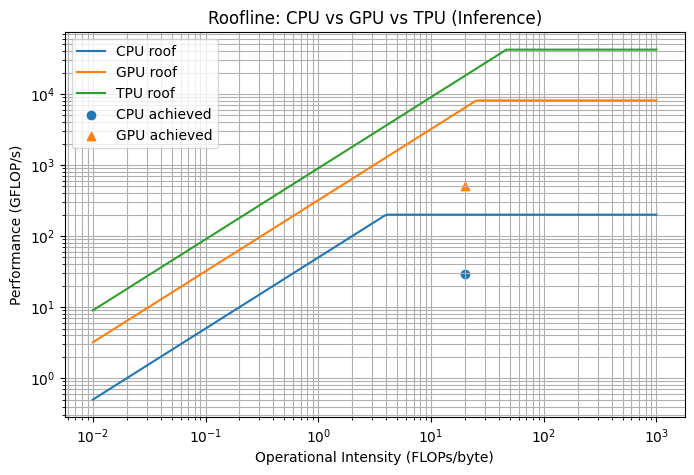

In [9]:
import numpy as np, matplotlib.pyplot as plt

# === TODO: Fill these with your sourced/assumed values ===
PEAK_GFLOPS_CPU = 200.0   # example placeholder
BW_GBPS_CPU     = 50.0    # example placeholder

PEAK_GFLOPS_GPU = 8100.0  # example placeholder (e.g., T4 ~8.1 TF16 / ~8.1 TF32 depends how you count)
BW_GBPS_GPU     = 320.0   # example placeholder

PEAK_GFLOPS_TPU = 42000.0 # example placeholder; replace with single-core spec if needed
BW_GBPS_TPU     = 900.0   # example placeholder

OI = 20.0  # FLOPs/byte (your assumption for inference)

def roofline(peak_gflops, bw_gbps, oi_vals):
    return np.minimum(peak_gflops, bw_gbps * oi_vals)

oi = np.logspace(-2, 3, 200)
plt.figure(figsize=(8,5))
plt.loglog(oi, roofline(PEAK_GFLOPS_CPU, BW_GBPS_CPU, oi), label='CPU roof')
plt.loglog(oi, roofline(PEAK_GFLOPS_GPU, BW_GBPS_GPU, oi), label='GPU roof')
plt.loglog(oi, roofline(PEAK_GFLOPS_TPU, BW_GBPS_TPU, oi), label='TPU roof')

# Overlay achieved points: choose the max achieved per device from df
def max_achieved(device):
    sub = df[df['device']==device]
    return sub['achieved_GOp_s'].max() if len(sub)>0 else None

cpu_gops = max_achieved('CPU')
gpu_gops = max_achieved('GPU')
tpu_gops = max_achieved('TPU')

if cpu_gops is not None: plt.scatter([OI],[cpu_gops], marker='o', label='CPU achieved')
if gpu_gops is not None: plt.scatter([OI],[gpu_gops], marker='^', label='GPU achieved')
if tpu_gops is not None: plt.scatter([OI],[tpu_gops], marker='s', label='TPU achieved')

plt.xlabel('Operational Intensity (FLOPs/byte)')
plt.ylabel('Performance (GFLOP/s)')
plt.title('Roofline: CPU vs GPU vs TPU (Inference)')
plt.grid(True, which='both')
plt.legend()
plt.show()